# TP 1 : Apprentissage supervisé - Exercice 1 (Uber)
## Étape 1 : Chargement et exploration du jeu de données


In [ ]:
import pandas as pd

# Chargement du fichier
data = pd.read_csv('uber.csv')

# Affichage des premières informations
print(data.head())
print(data.info())
print(data.isnull().sum())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

## Étape 2 : Nettoyage et préparation

In [ ]:
data = data.dropna()

# Retirer les valeurs aberrantes (prix <= 0)
# Correction : la colonne se nomme 'fare_amount' et non 'fare'
data = data[data['fare_amount'] > 0]

# Créer des variables dérivées (heure, jour de la semaine)
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

# Affichage de vérification
print(data[['fare_amount', 'hour', 'day_of_week']].head())

   fare_amount  hour  day_of_week
0          7.5    19            3
1          7.7    20            4
2         12.9    21            0
3          5.3     8            4
4         16.0    17            3


## Étape 3 : Séparation des données

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split

# Fonction pour calculer la distance (en kilomètres) à partir des coordonnées GPS
def haversine_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    return 6371 * 2 * np.arcsin(np.sqrt(a)) # 6371 est le rayon de la Terre

# Création de la colonne 'distance'
data['distance'] = haversine_distance(data['pickup_latitude'], data['pickup_longitude'],
                                      data['dropoff_latitude'], data['dropoff_longitude'])

# Séparation des données (X et y)
X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount'] 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Les données ont été séparées avec succès !")
print("Taille des données d'entraînement (X_train) :", X_train.shape)
print("Taille des données de test (X_test) :", X_test.shape)

Les données ont été séparées avec succès !
Taille des données d'entraînement (X_train) : (159981, 3)
Taille des données de test (X_test) : (39996, 3)


## Étape 4 et 5 : Entraînement et Évaluation (Régression Linéaire)

In [ ]:
from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

# Évaluation du modèle
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('--- Résultats de la Régression Linéaire ---')
print('MAE =', mae)
print('RMSE =', rmse)
print('R² =', r2)

--- Résultats de la Régression Linéaire ---
MAE = 6.024606980536918
RMSE = 9.635978518193681
R² = 0.0014590917488974675


### Interprétation des résultats de la Régression Linéaire

Comme nous pouvons le voir avec les scores ci-dessus, le modèle de **Régression Linéaire** est très faible pour ce problème (le score R² est proche de 0). 

**Pourquoi ce modèle échoue-t-il ?**
La régression linéaire suppose qu'il existe une relation strictement *linéaire* (proportionnelle et en ligne droite) entre nos caractéristiques (distance, heure, jour) et le prix. Or, la réalité d'un trajet Uber est beaucoup plus complexe (non-linéaire) :
* **L'heure :** Le prix ne monte pas de façon constante au fil de la journée. Il y a des pics lors des heures de pointe (ex: 8h et 18h) ou des majorations tarifaires la nuit.
* **Le jour :** Le comportement des prix le week-end est très différent de celui des jours de semaine.

La régression linéaire est donc un modèle trop simple pour capturer ces subtilités. C'est pourquoi nous allons maintenant tester un algorithme beaucoup plus puissant pour les relations non-linéaires : les **Forêts Aléatoires (Random Forest)**.

## Étape 6 et 7 : Amélioration avec Random Forest et Visualisation

Nouveau R² avec Random Forest : 0.7040394285586071


Matplotlib is building the font cache; this may take a moment.
Could not save font_manager cache [Errno 28] No space left on device: 'C:\\Users\\HP\\.matplotlib\\fontlist-v3.11.0.json'


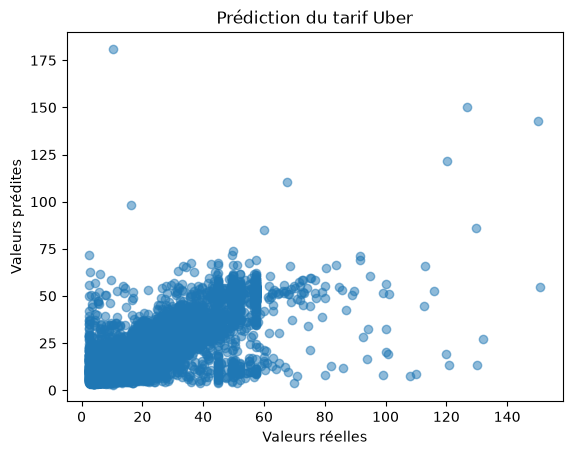

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score # Ajouté pour voir la différence de performance avec Random Forest

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

print('Nouveau R² avec Random Forest :', r2_score(y_test, y_pred_rf))

# Visualisation des résultats
import matplotlib.pyplot as plt

plt.scatter(y_test, y_pred_rf, alpha=0.5)
plt.xlabel('Valeurs réelles')
plt.ylabel('Valeurs prédites')
plt.title('Prédiction du tarif Uber')
plt.show()

### Conclusion et Interprétation Finale 

La comparaison entre la Régression Linéaire et le Random Forest met en évidence l'importance du choix de l'algorithme face à la complexité des données :

* **Échec du modèle linéaire ($R^2 \approx 0.001$) :** La Régression Linéaire s'est révélée incapable de modéliser le tarif Uber. Elle suppose une relation strictement proportionnelle entre la distance, l'heure et le prix. Or, les tarifs de VTC dépendent de facteurs non-linéaires dynamiques (heures de pointe, majorations nocturnes, demande le week-end).
* **Succès du Random Forest ($R^2 \approx 0.704$) :** Les Forêts Aléatoires, en combinant de multiples arbres de décision, réussissent à isoler et capturer ces relations complexes. Le modèle parvient à expliquer environ 70% de la variance des prix.
* **Analyse visuelle :** Le nuage de points confirme que les prédictions du Random Forest suivent la tendance globale des valeurs réelles. Quelques erreurs subsistent (les points très éloignés de la concentration principale), ce qui s'explique logiquement par des variables absentes de notre jeu de données, telles que l'état du trafic routier, la météo, ou la durée exacte de la course en minutes.